# Kr sensitivity

Uncertainty of the sample partial pressure $P_\mathrm{sample}(A)$ and the resulting resolution versus concentration,
following `notes/202611.tex` ("RGA Krypton Measurement Uncertainties and Sensitivity").
Drift and correlated uncertainties are ignored, as in the note.

In [1]:
from xenonnt_plot_style import XENONPlotStyle as xps
xps.use('xenonnt')

In [2]:
import os
import numpy as np
from scipy.optimize import brentq
import matplotlib.pyplot as plt

In [3]:
from utils import read_rga_file, get_t0

In [4]:
folder = '../../Documents/RGAData/PressurevsTime'
# folder = '../rga'

In [5]:
filenames = [
    'PressurevsTime-20261102-171546-393.txt',
]

In [6]:
masses = [87, 28, 40, 62, 84]

# Reference (empty) channel and the channel of interest, A in the note
ref = 87
A = 84

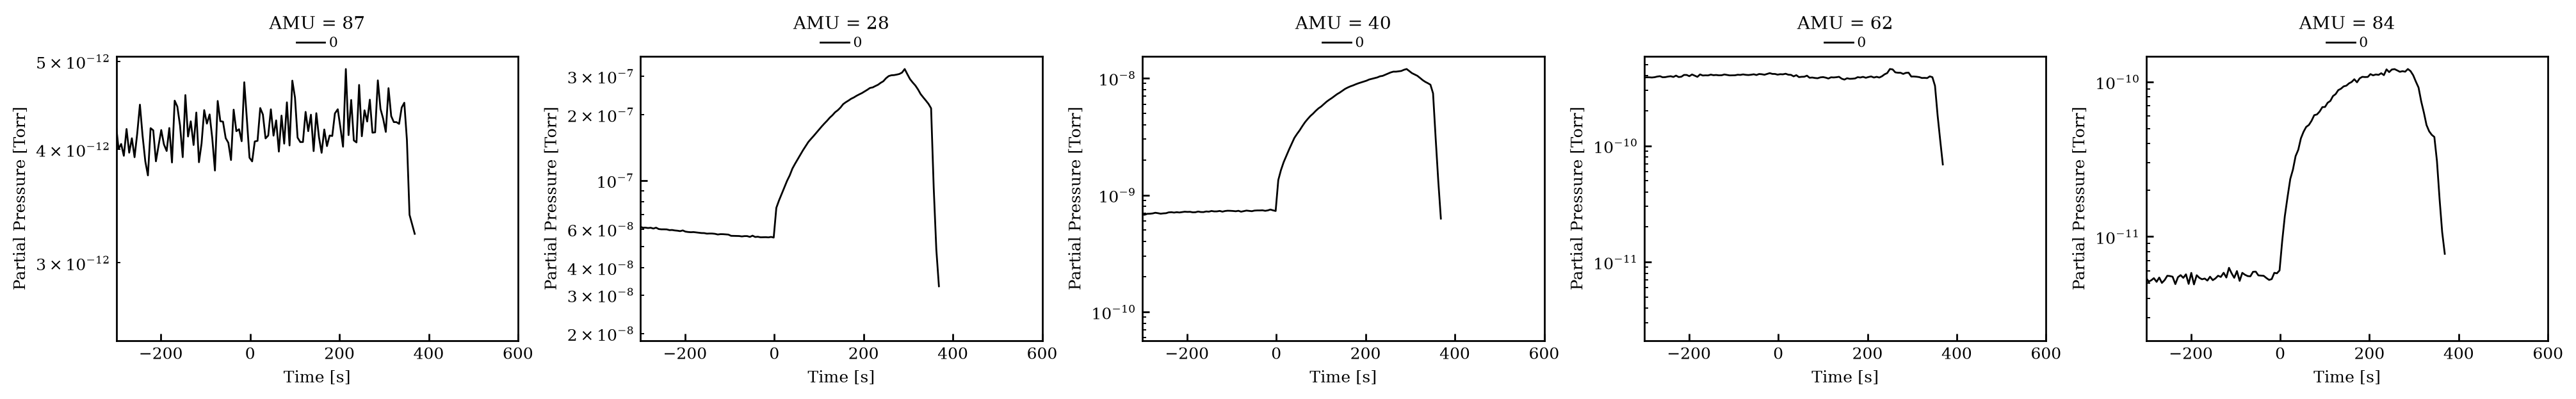

In [7]:
fig, axes = plt.subplots(1, len(masses), figsize=(4 * len(masses), 3))

for i, (ax, mass) in enumerate(zip(axes, masses)):
    for j, filename in enumerate(filenames):
        rga = read_rga_file(os.path.join(folder, filename))
        t0 = get_t0(rga['t'], rga[28])
        ax.plot(rga['t'] - t0, rga[mass], label=j)

    ax.legend(title=f'AMU = {mass}', ncols=len(filenames))
    ax.set_xlabel('Time [s]')
    ax.set_ylabel('Partial Pressure [Torr]')
    ax.set_yscale('log')
    ax.set_xlim(-300, 600)

plt.show()

## Data and windows

The analysis below uses a single file. Both runs are taken from it:

* background run ($_\mathrm{bkg}$): the 300 s before $t_0$, RGA exposed only to the ice primer
* flow run ($_\mathrm{flw}$): $t_0 - 10$ s to $t_0 + 250$ s, the same window as `get_integral`

In [8]:
rga = read_rga_file(os.path.join(folder, filenames[0]))
t = rga['t']
t0 = get_t0(t, rga[28])

mask_bkg = (t > t0 - 300) & (t < t0)
mask_flw = (t > t0 + 5) & (t < t0 + 250)

N_bkg = mask_bkg.sum()
N_flw = mask_flw.sum()

N_bkg, N_flw

(np.int64(50), np.int64(40))

Assumption (note, first box): the time intervals between successive groups of AMU measurements are equal.

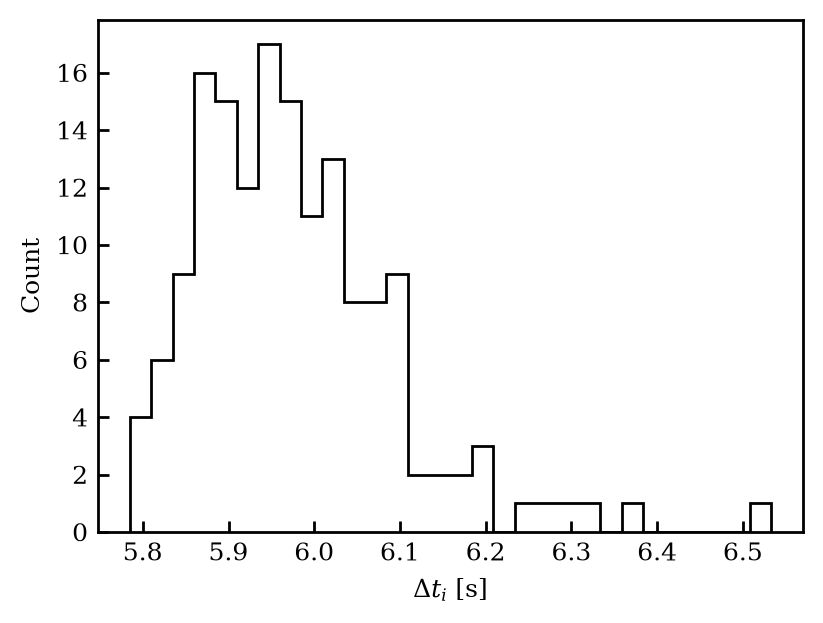

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(4, 3))

ax.hist(np.diff(t), bins=30, histtype='step')

ax.set_xlabel('$\Delta t_i$ [s]')
ax.set_ylabel('Count')

plt.show()

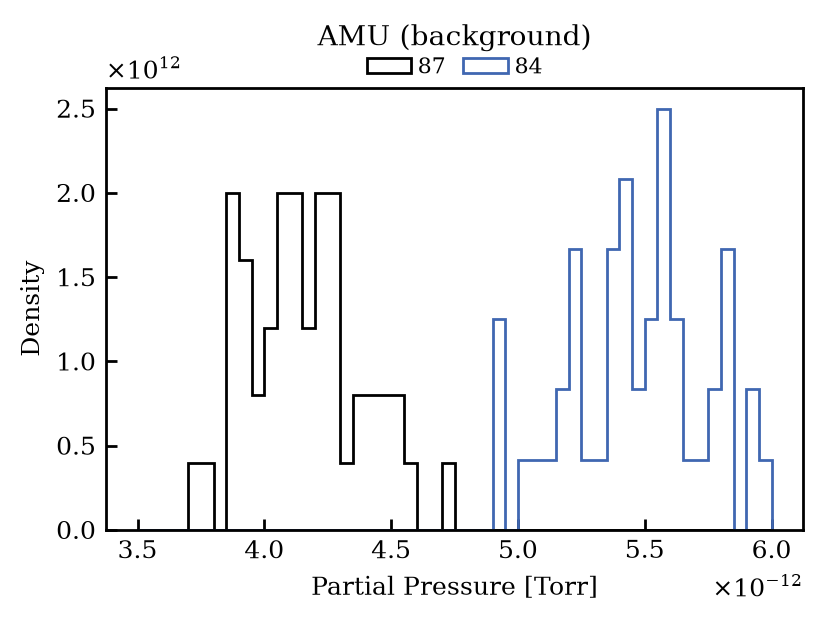

In [10]:
bins = np.linspace(3.5e-12, 6e-12, 51)

fig, ax = plt.subplots(1, 1, figsize=(4, 3))

for mass in [ref, A]:
    ax.hist(rga[mass][mask_bkg], bins=bins, density=True, histtype='step', label=mass)

ax.legend(title='AMU (background)', ncols=2)
ax.set_xlabel('Partial Pressure [Torr]')
ax.set_ylabel('Density')

plt.show()

## Measured quantities

Reference-subtracted partial pressure for each group, $\Delta p_k(A) = p_k(A) - p_k(87)$, and the run averages
$$P_\mathrm{flw}(A) = \frac{1}{N_\mathrm{flw}}\sum_i \Delta p_i(A), \qquad P_\mathrm{bkg}(A) = \frac{1}{N_\mathrm{bkg}}\sum_j \Delta p_j(A).$$

$\sigma_{0,\mathrm{bkg}}$ and $\sigma_{0,\mathrm{flw}}$ are estimated **separately**, from the sample standard deviations of $p_j(87)$ and $p_i(87)$ in each run.
$\sigma_\mathrm{bkg}(A)$ is the sample standard deviation of the raw background readings $p_j(A)$, and
$$c = \frac{\sigma_\mathrm{bkg}(A)/\sigma_{0,\mathrm{bkg}} - 1}{P_\mathrm{bkg}(A)}.$$

In [11]:
dp_bkg = rga[A][mask_bkg] - rga[ref][mask_bkg]
dp_flw = rga[A][mask_flw] - rga[ref][mask_flw]

P_bkg = dp_bkg.mean()
P_flw = dp_flw.mean()

sigma_0_bkg = np.std(rga[ref][mask_bkg], ddof=1)
sigma_0_flw = np.std(rga[ref][mask_flw], ddof=1)
sigma_bkg_A = np.std(rga[A][mask_bkg], ddof=1)

c = (sigma_bkg_A / sigma_0_bkg - 1) / P_bkg

In [12]:
print(f'P_bkg       = {P_bkg:.3e} Torr')
print(f'P_flw       = {P_flw:.3e} Torr')
print(f'sigma_0,bkg = {sigma_0_bkg:.3e} Torr')
print(f'sigma_0,flw = {sigma_0_flw:.3e} Torr')
print(f'sigma_bkg(A)/sigma_0,bkg = {sigma_bkg_A / sigma_0_bkg:.3f}')
print(f'c           = {c / 1e12:.3f} pTorr^-1')
print(f'c * P_bkg   = {c * P_bkg:.3f}')
print(f'c * P_flw   = {c * P_flw:.3f}')

P_bkg       = 1.338e-12 Torr
P_flw       = 7.423e-11 Torr
sigma_0,bkg = 2.227e-13 Torr
sigma_0,flw = 2.285e-13 Torr
sigma_bkg(A)/sigma_0,bkg = 1.352
c           = 0.263 pTorr^-1
c * P_bkg   = 0.352
c * P_flw   = 19.552


## Uncertainty of $P_\mathrm{sample}(A) = P_\mathrm{flw}(A) - P_\mathrm{bkg}(A)$

Background contribution, assuming $\Delta p_j(A) \approx P_\mathrm{bkg}(A)$:
$$\sigma^2_{P_\mathrm{bkg}(A)} \approx \frac{\sigma^2_{0,\mathrm{bkg}}}{N_\mathrm{bkg}}\left\{1 + \left[1 + c P_\mathrm{bkg}(A)\right]^2\right\}.$$

Low-concentration limit, $|c\,\Delta p_i(A)| \ll 1$:
$$\sigma^2_{P_\mathrm{sample}(A)} \approx \frac{\sigma^2_{0,\mathrm{flw}}}{N_\mathrm{flw}}\left[2 + 2cP_\mathrm{flw}(A)\right] + \sigma^2_{P_\mathrm{bkg}(A)}.$$

High-concentration limit, $c\,\Delta p_i(A) \gg 1$:
$$\sigma^2_{P_\mathrm{sample}(A)} \approx \frac{\sigma^2_{0,\mathrm{flw}}c^2}{N_\mathrm{flw}^2}\sum_i \Delta p_i(A)^2 + \sigma^2_{P_\mathrm{bkg}(A)}.$$

To scan the concentration, the measured flow profile $\Delta p_i(A)$ is scaled so that its mean is $x$;
the background run, $N$'s and $\sigma_0$'s are kept fixed.

In [13]:
# Background variance, fixed for all concentrations
var_P_bkg = sigma_0_bkg ** 2 / N_bkg * (1 + (1 + c * P_bkg) ** 2)


def sigma_low(x):
    """Low-concentration limit of sigma_P_sample for P_flw = x."""
    var_P_flw = sigma_0_flw ** 2 / N_flw * (2 + 2 * c * x)
    return np.sqrt(var_P_flw + var_P_bkg)


def sigma_high(x):
    """High-concentration limit of sigma_P_sample, measured flow profile scaled to mean x."""
    sum_dp2 = (x / P_flw) ** 2 * np.sum(dp_flw ** 2)
    var_P_flw = sigma_0_flw ** 2 * c ** 2 / N_flw ** 2 * sum_dp2
    return np.sqrt(var_P_flw + var_P_bkg)

In [14]:
# At the measured concentration
print(f'sigma (low-concentration limit)  = {sigma_low(P_flw):.3e} Torr')
print(f'sigma (high-concentration limit) = {sigma_high(P_flw):.3e} Torr')

sigma (low-concentration limit)  = 2.376e-13 Torr
sigma (high-concentration limit) = 7.666e-13 Torr


## Resolution versus concentration

The measured run is taken as $10^3$ ppq (as in the previous version of this notebook), so concentration $= x / P_\mathrm{flw} \times 10^3$ ppq.

In [15]:
ppq_per_P = 1e3 / P_flw  # concentration [ppq] per Torr of P_sample

x = np.geomspace(1e-4 * P_flw, 1e3 * P_flw, 1001)
conc = x * ppq_per_P

## Sensitivity

The sensitivity is the concentration at which the true concentration equals $n_\sigma = 3$ times its uncertainty,
$x = 3\,\sigma_{P_\mathrm{sample}}(x)$, i.e. the intersection of the resolution curves with $x / 3$
(relative resolution $= 1/3$).

In [16]:
n_sigma = 3


def get_sensitivity(sigma):
    """Concentration x [Torr] where x = n_sigma * sigma(x), searched on the grid x."""
    f = lambda xx: n_sigma * sigma(xx) - xx
    i = np.flatnonzero(np.diff(np.sign(f(x))) != 0)[0]
    return brentq(f, x[i], x[i + 1])


sensitivity = {
    'High Concentration': get_sensitivity(sigma_high),
    'Low Concentration': get_sensitivity(sigma_low),
}

for label, s in sensitivity.items():
    print(f'{label}: {s:.3e} Torr = {s * ppq_per_P:.2f} ppq')

High Concentration: 1.587e-13 Torr = 2.14 ppq
Low Concentration: 2.226e-13 Torr = 3.00 ppq


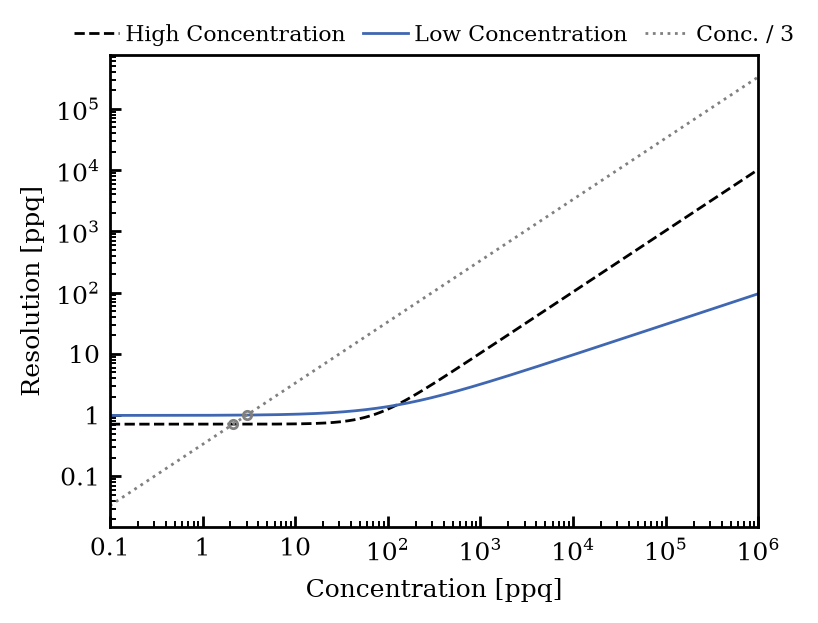

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(4, 3))

ax.plot(conc, sigma_high(x) * ppq_per_P, label='High Concentration', linestyle='dashed')
ax.plot(conc, sigma_low(x) * ppq_per_P, label='Low Concentration')
ax.plot(conc, conc / n_sigma, color='gray', linestyle='dotted', label=f'Conc. / {n_sigma}')

for s in sensitivity.values():
    ax.plot(s * ppq_per_P, s * ppq_per_P / n_sigma, 'o', color='gray', markerfacecolor='none')

ax.legend(ncols=3)
ax.set_xlabel('Concentration [ppq]')
ax.set_ylabel('Resolution [ppq]')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(conc[0], conc[-1])

plt.show()

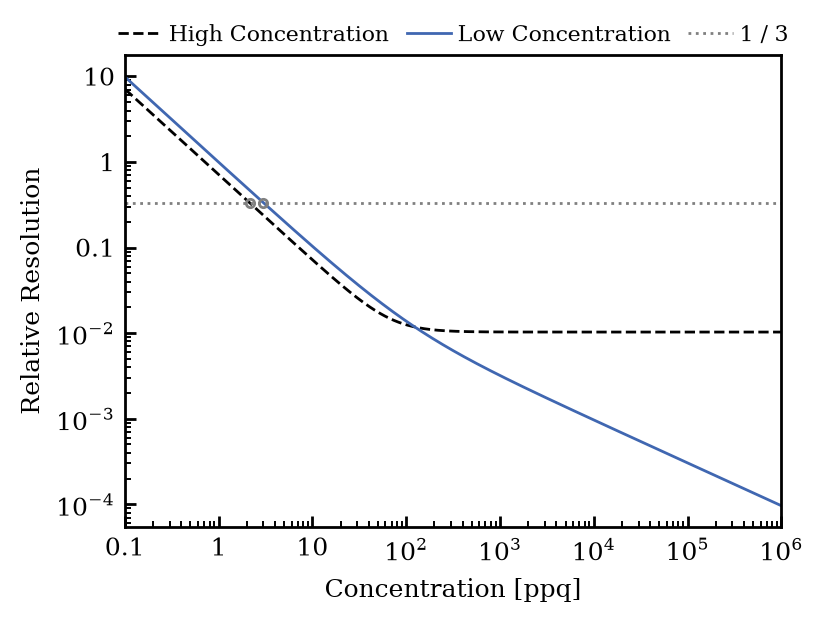

In [18]:
fig, ax = plt.subplots(1, 1, figsize=(4, 3))

ax.plot(conc, sigma_high(x) / x, label='High Concentration', linestyle='dashed')
ax.plot(conc, sigma_low(x) / x, label='Low Concentration')
ax.axhline(1 / n_sigma, color='gray', linestyle='dotted', label=f'1 / {n_sigma}')

for s in sensitivity.values():
    ax.plot(s * ppq_per_P, 1 / n_sigma, 'o', color='gray', markerfacecolor='none')

ax.legend(ncols=3)
ax.set_xlabel('Concentration [ppq]')
ax.set_ylabel('Relative Resolution')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(conc[0], conc[-1])

plt.show()